# Vehicle Insurance Cross-Sell Prediction

## Business Problem

An insurance company currently sells Health Insurance to its customers and wants to know which of those customers would also be interested in **Vehicle Insurance**. Buying interest is not random — it depends on demographics (age, gender), the customer's vehicle (age, prior damage), and their existing policy (premium, sourcing channel, tenure).

If the company could rank customers by their likelihood of buying, it could:

- Target outbound calls/emails at high-propensity customers instead of the entire base
- Cut wasted marketing spend on customers who are very unlikely to convert
- Increase the cross-sell conversion rate and, in turn, revenue per existing customer

## Objective

Build a supervised classification model that outputs a **propensity-to-buy score** for each customer, evaluate it rigorously (with a business-relevant metric, not just accuracy), explain *why* it makes each prediction, and translate the findings into concrete targeting recommendations.

## Notebook Structure

1. Setup & Data Loading
2. Data Understanding & Quality Checks
3. Exploratory Data Analysis
4. Feature Engineering
5. Train/Validation Split & Class Imbalance Handling
6. Baseline Model Comparison (Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost)
7. Hyperparameter Optimization (Optuna)
8. Final Model Evaluation
9. Model Explainability (SHAP)
10. Business Insights & Recommendations


## Executive Summary

This project develops a machine learning solution to identify existing health insurance customers who are most likely to purchase vehicle insurance. The objective is to help insurance companies optimize cross-selling campaigns, improve customer targeting, reduce marketing costs, and maximize return on investment (ROI).

### Key Highlights

- Built an end-to-end machine learning pipeline for customer response prediction.
- Compared five machine learning models: Logistic Regression, Random Forest, XGBoost, LightGBM, and CatBoost.
- Optimized the best-performing model using Optuna for automated hyperparameter tuning.
- Achieved a validation ROC-AUC score of approximately **0.856**, demonstrating strong discrimination between responders and non-responders.
- Applied SHAP (SHapley Additive exPlanations) to interpret feature importance and explain individual predictions.
- Performed threshold optimization and lift analysis, showing that targeting the top 10% of customers captures approximately **31.9% of all potential responders**, corresponding to a **3.2× improvement over random targeting**.
- Concluded with business recommendations to support more efficient marketing campaigns and data-driven decision making.

## 1. Setup & Data Loading

In [7]:
# ============================================================
# Install required libraries (Run once in Google Colab)
# ============================================================

!pip install -q catboost lightgbm optuna shap xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 10.1 MB/s eta 0:00:00


In [8]:
# Core libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                              f1_score, precision_score, recall_score, accuracy_score,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import shap

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

In [9]:
# Colab-friendly data loading.
# If running in Google Colab and the CSVs are not already present, this
# prompts a local file upload. If running locally / files already present
# (e.g. already uploaded to the Colab session or sitting next to this
# notebook), it just reads them directly.
import os

DATA_FILES = ['train.csv', 'test.csv', 'sample_submission.csv']

def in_colab():
    try:
        import google.colab  # noqa
        return True
    except ImportError:
        return False

if in_colab() and not all(os.path.exists(f) for f in DATA_FILES):
    from google.colab import files
    print('Please upload train.csv, test.csv, and sample_submission.csv')
    uploaded = files.upload()

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print(f'Train shape: {train.shape}')
print(f'Test shape (unlabeled, held by the original competition): {test.shape}')

Train shape: (381109, 12)
Test shape (unlabeled, held by the original competition): (127037, 11)


## 2. Data Understanding & Quality Checks

`test.csv` has no `Response` column — it's an unlabeled scoring set from the original competition, so it **cannot** be used to evaluate the model. All model training, validation, and hyperparameter tuning below uses an internal split of `train.csv` only.

In [10]:
train.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [11]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [12]:
print('Missing values per column:')
print(train.isnull().sum())
print()
print('Duplicate rows:', train.duplicated().sum())
print('Duplicate customer ids:', train['id'].duplicated().sum())

Missing values per column:
id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64

Duplicate rows: 0
Duplicate customer ids: 0


In [13]:
train[['Age', 'Region_Code', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage']].describe()

,Age,Region_Code,Annual_Premium,Policy_Sales_Channel,Vintage
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,38.822584,26.388807,30564.389581,112.034295,154.347397
std,15.511611,13.229888,17213.155057,54.203995,83.671304
min,20.000000,0.000000,2630.000000,1.000000,10.000000
25%,25.000000,15.000000,24405.000000,29.000000,82.000000
50%,36.000000,28.000000,31669.000000,133.000000,154.000000
75%,49.000000,35.000000,39400.000000,152.000000,227.000000
max,85.000000,52.000000,540165.000000,163.000000,299.000000


## 3. Exploratory Data Analysis

### 3.1 Target Variable

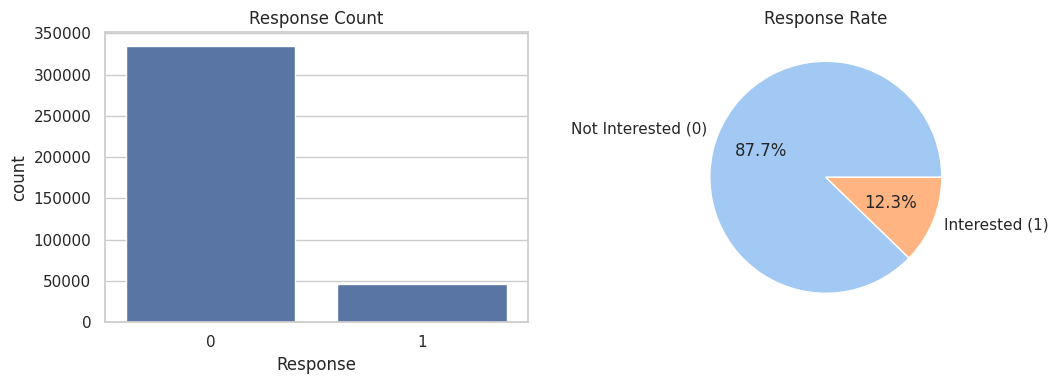

Positive class (Interested) rate: 12.26%


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='Response', data=train, ax=ax[0])
ax[0].set_title('Response Count')
response_rate = train['Response'].value_counts(normalize=True)
ax[1].pie(response_rate, labels=['Not Interested (0)', 'Interested (1)'], autopct='%1.1f%%',
          colors=sns.color_palette('pastel')[:2])
ax[1].set_title('Response Rate')
plt.tight_layout()
plt.show()

print(f"Positive class (Interested) rate: {response_rate[1]*100:.2f}%")

Only ~12.3% of customers are interested in vehicle insurance. This is a meaningfully **imbalanced classification problem** — a model that predicts "not interested" for everyone would already be ~88% "accurate" while being completely useless for targeting. This is exactly why accuracy is the wrong headline metric here (more on this in Section 6).

### 3.2 Numeric Features

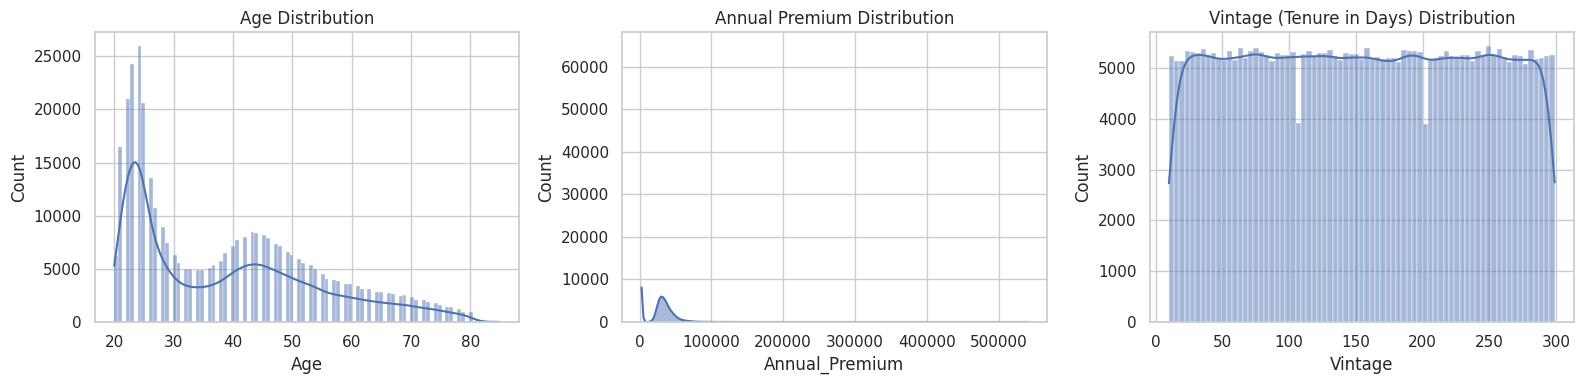

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train['Age'], kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')
sns.histplot(train['Annual_Premium'], kde=True, ax=axes[1])
axes[1].set_title('Annual Premium Distribution')
sns.histplot(train['Vintage'], kde=True, ax=axes[2])
axes[2].set_title('Vintage (Tenure in Days) Distribution')
plt.tight_layout()
plt.show()

`Annual_Premium` is heavily right-skewed with a long tail of high-premium customers — this motivates a log transform during feature engineering.

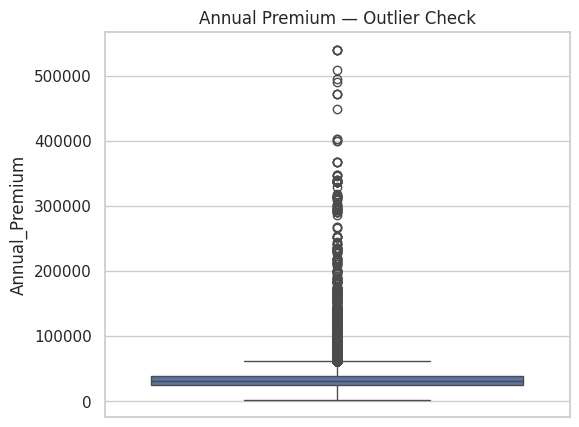

99th percentile Annual Premium: 72,963
Max Annual Premium: 540,165


In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(y='Annual_Premium', data=train, ax=ax)
ax.set_title('Annual Premium — Outlier Check')
plt.show()

p99 = train['Annual_Premium'].quantile(0.99)
print(f"99th percentile Annual Premium: {p99:,.0f}")
print(f"Max Annual Premium: {train['Annual_Premium'].max():,.0f}")

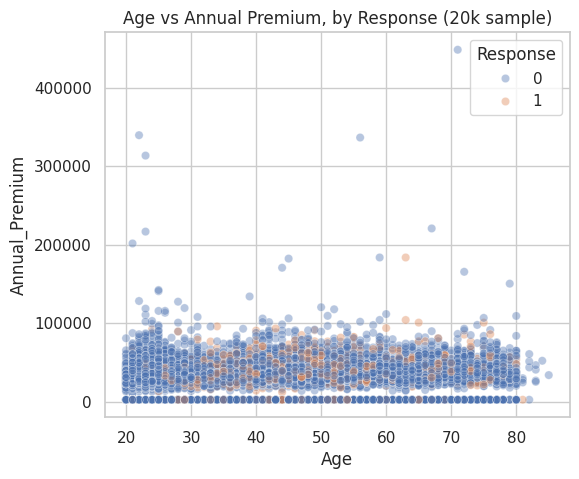

In [17]:
plt.figure(figsize=(6, 5))
sns.scatterplot(x='Age', y='Annual_Premium', hue='Response', data=train.sample(20000, random_state=RANDOM_STATE),
                 alpha=0.4, palette=['#4C72B0', '#DD8452'])
plt.title('Age vs Annual Premium, by Response (20k sample)')
plt.show()

### 3.3 Categorical Features vs Response

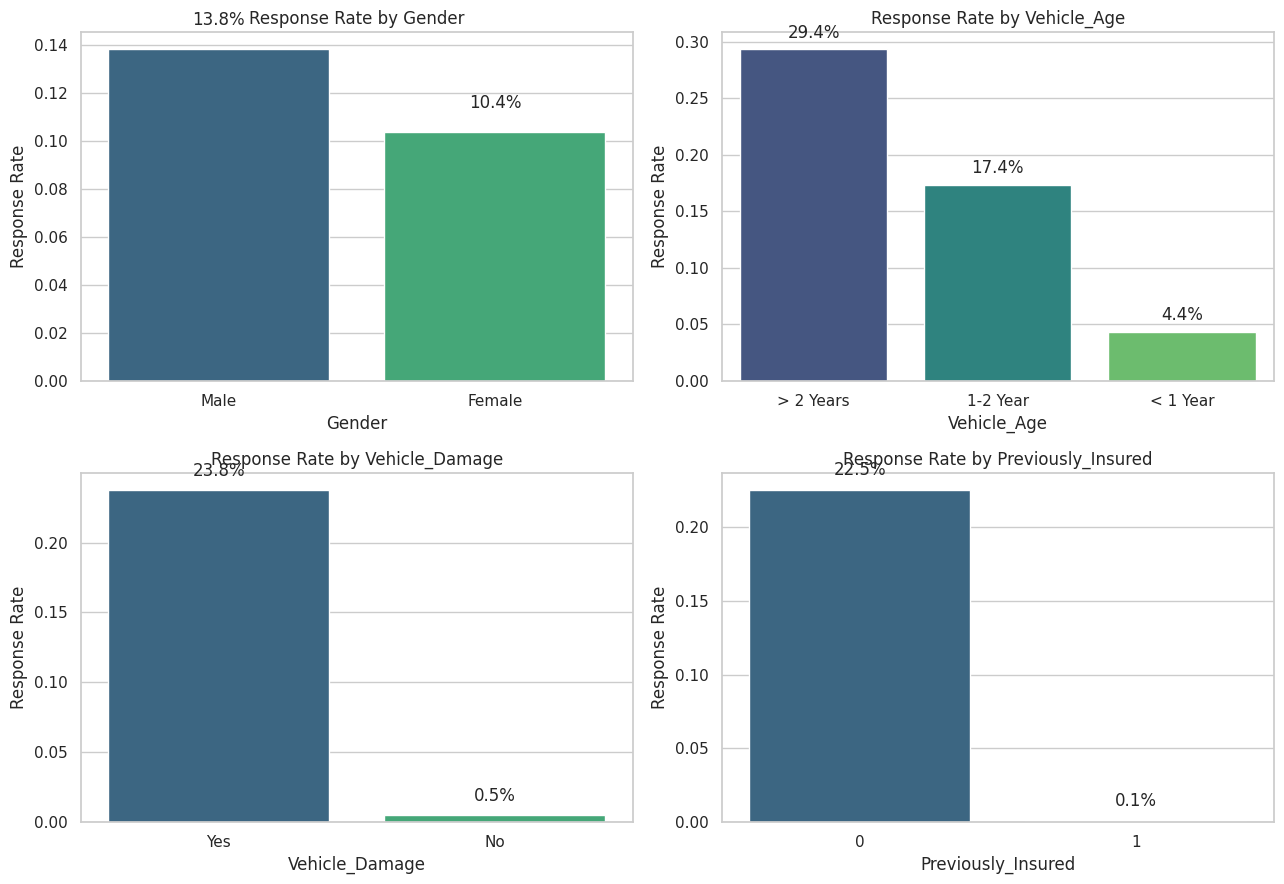

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, ax in zip(['Gender', 'Vehicle_Age', 'Vehicle_Damage', 'Previously_Insured'], axes.ravel()):
    rate = train.groupby(col)['Response'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette='viridis')
    ax.set_ylabel('Response Rate')
    ax.set_title(f'Response Rate by {col}')
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.01, f'{v:.1%}', ha='center')

plt.tight_layout()
plt.show()

A few patterns jump out immediately:

- **`Vehicle_Damage`** is the single strongest split: customers whose vehicle was previously damaged convert far more often than those whose vehicle wasn't.
- **`Previously_Insured`** customers (already covered for their vehicle) almost never respond — makes intuitive sense, there's nothing to cross-sell.
- **`Vehicle_Age`** shows a monotonic relationship: older vehicles → higher response rate.
- **`Gender`** shows only a small gap and is unlikely to be a strong standalone predictor.

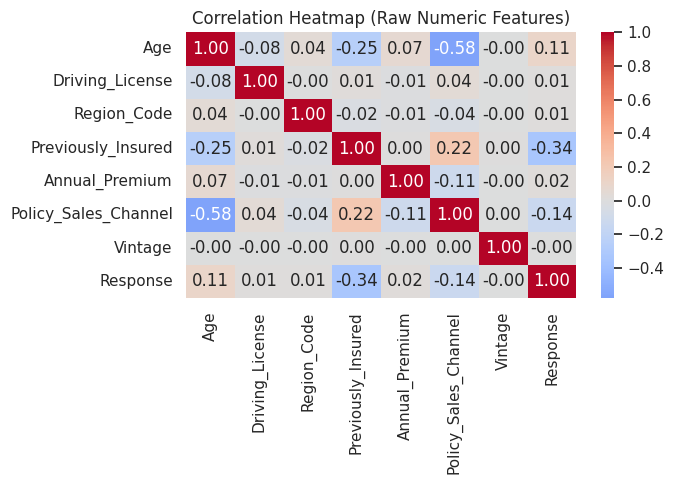

In [19]:
plt.figure(figsize=(7, 5))
corr_cols = ['Age', 'Driving_License', 'Region_Code', 'Previously_Insured',
             'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response']
sns.heatmap(train[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (Raw Numeric Features)')
plt.tight_layout()
plt.show()

No raw numeric feature is strongly correlated with `Response` in isolation — this is a signal that the real predictive power will come from **categorical splits and engineered interactions**, not a single linear numeric driver, which is consistent with `Vehicle_Damage` and `Previously_Insured` standing out above.

## 4. Feature Engineering

Design choices, each with a stated rationale:

| Feature | Rationale |
|---|---|
| `Gender_Male` | Binary-encode the 2-level categorical |
| `Vehicle_Damage_Yes` | Binary-encode the 2-level categorical |
| `Vehicle_Age_ordinal` | `Vehicle_Age` is naturally ordered (`< 1` → `1-2` → `> 2` years); encoding it ordinally instead of one-hot preserves that order for the model |
| `Premium_log` | `Annual_Premium` is heavily right-skewed (Section 3.2); a log transform reduces the influence of extreme outliers |
| `Premium_per_Vintage_Day` | Premium relative to how long the customer has been with the company — a proxy for "value density" of the relationship |
| `No_Insurance_Damaged` | Interaction flag for customers with **no prior vehicle insurance AND a history of vehicle damage** — the EDA above suggests this combination is a high-propensity segment |
| `Region_Freq`, `Channel_Freq` | `Region_Code` and `Policy_Sales_Channel` are high-cardinality numeric IDs (50+ / 150+ unique values) with no inherent ordering — raw numeric IDs are not meaningful to a model, and one-hot encoding them would blow up dimensionality. Frequency encoding turns each code into "how common is this region/channel", computed **from the training split only** to avoid leakage into validation |

`Driving_License` is already binary and is kept as-is.

In [20]:
def engineer_features(df, region_freq=None, channel_freq=None, fit=False):
    """Feature engineering, with frequency-encoding maps fit only on training data
    (fit=True) and re-applied to validation/test data (fit=False) to avoid leakage."""
    df = df.copy()

    df['Gender_Male'] = (df['Gender'] == 'Male').astype(int)
    df['Vehicle_Damage_Yes'] = (df['Vehicle_Damage'] == 'Yes').astype(int)

    vehicle_age_map = {'< 1 Year': 0, '1-2 Year': 1, '> 2 Years': 2}
    df['Vehicle_Age_ordinal'] = df['Vehicle_Age'].map(vehicle_age_map)

    df['Premium_log'] = np.log1p(df['Annual_Premium'])
    df['Premium_per_Vintage_Day'] = df['Annual_Premium'] / (df['Vintage'] + 1)

    df['No_Insurance_Damaged'] = (
        (df['Previously_Insured'] == 0) & (df['Vehicle_Damage_Yes'] == 1)
    ).astype(int)

    if fit:
        region_freq = df['Region_Code'].value_counts(normalize=True)
        channel_freq = df['Policy_Sales_Channel'].value_counts(normalize=True)

    df['Region_Freq'] = df['Region_Code'].map(region_freq).fillna(0)
    df['Channel_Freq'] = df['Policy_Sales_Channel'].map(channel_freq).fillna(0)

    return df, region_freq, channel_freq


FEATURES = [
    'Age', 'Vintage', 'Premium_log', 'Premium_per_Vintage_Day',
    'Region_Freq', 'Channel_Freq', 'Gender_Male', 'Driving_License',
    'Previously_Insured', 'Vehicle_Age_ordinal', 'Vehicle_Damage_Yes',
    'No_Insurance_Damaged',
]

train_fe, region_freq_map, channel_freq_map = engineer_features(train, fit=True)
train_fe[FEATURES].head()

,Age,Vintage,Premium_log,Premium_per_Vintage_Day,Region_Freq,Channel_Freq,Gender_Male,Driving_License,Previously_Insured,Vehicle_Age_ordinal,Vehicle_Damage_Yes,No_Insurance_Damaged
0,44,217,10.607946,185.568807,0.279225,0.209127,1,1,0,2,1,1
1,76,183,10.420405,182.260870,0.024274,0.209127,1,1,0,1,0,0
2,47,27,10.553075,1367.642857,0.279225,0.209127,1,1,0,2,1,1
3,21,203,10.261861,140.289216,0.024224,0.353663,1,1,1,0,0,0
4,29,39,10.221832,687.400000,0.047921,0.353663,0,1,1,0,0,0


## 5. Train/Validation Split & Class Imbalance Handling

A stratified 80/20 split preserves the ~12.3% positive rate in both partitions. Because the classes are imbalanced, every boosting model below is trained with `scale_pos_weight` (or `class_weight='balanced'` for the linear/RF models) so that the ~7:1 majority class doesn't dominate the loss function.

In [21]:
X = train_fe[FEATURES]
y = train_fe['Response']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print(f'Train shape: {X_train.shape}, Val shape: {X_val.shape}')
print(f'Train positive rate: {y_train.mean():.4f}, Val positive rate: {y_val.mean():.4f}')
print(f'scale_pos_weight (majority/minority ratio): {scale_pos_weight:.3f}')

Train shape: (304887, 12), Val shape: (76222, 12)
Train positive rate: 0.1226, Val positive rate: 0.1226
scale_pos_weight (majority/minority ratio): 7.159


## 6. Baseline Model Comparison

Five models, same train/validation split, same feature set: Logistic Regression (linear baseline), Random Forest, XGBoost, LightGBM, and CatBoost. All are evaluated on **ROC-AUC**, not accuracy — with an 88/12 class split, accuracy barely moves even for a useless model, while ROC-AUC directly measures how well the model *ranks* interested customers above uninterested ones, which is exactly what a targeting use case needs.

In [22]:
results = {}

# --- Logistic Regression (needs scaling) ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
lr.fit(X_train_scaled, y_train)
results['Logistic Regression'] = roc_auc_score(y_val, lr.predict_proba(X_val_scaled)[:, 1])

# --- Random Forest ---
rf = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced',
                             random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
results['Random Forest'] = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])

# --- XGBoost ---
xgb_clf = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                             scale_pos_weight=scale_pos_weight, eval_metric='auc',
                             tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1)
xgb_clf.fit(X_train, y_train)
results['XGBoost'] = roc_auc_score(y_val, xgb_clf.predict_proba(X_val)[:, 1])

# --- LightGBM ---
lgb_clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05,
                              scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE,
                              n_jobs=-1, verbosity=-1)
lgb_clf.fit(X_train, y_train)
results['LightGBM'] = roc_auc_score(y_val, lgb_clf.predict_proba(X_val)[:, 1])

# --- CatBoost ---
cb_clf = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1,
                             class_weights=[1, scale_pos_weight],
                             random_state=RANDOM_STATE, verbose=0)
cb_clf.fit(X_train, y_train)
results['CatBoost'] = roc_auc_score(y_val, cb_clf.predict_proba(X_val)[:, 1])

results_df = pd.DataFrame(results.items(), columns=['Model', 'Validation ROC-AUC']).sort_values(
    'Validation ROC-AUC', ascending=False).reset_index(drop=True)
results_df

,Model,Validation ROC-AUC
0,LightGBM,0.857345
1,CatBoost,0.857145
2,XGBoost,0.856042
3,Random Forest,0.853964
4,Logistic Regression,0.833967


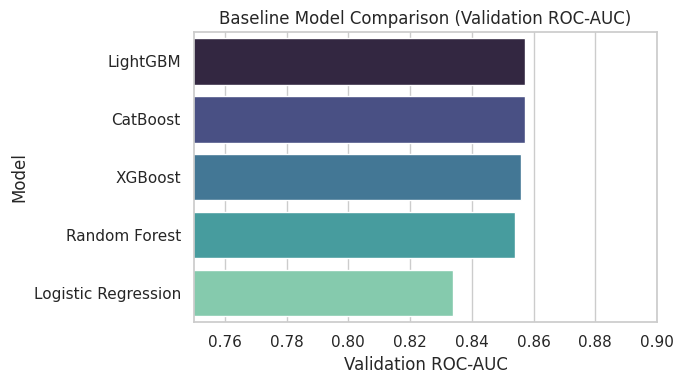

In [23]:
plt.figure(figsize=(7, 4))
sns.barplot(x='Validation ROC-AUC', y='Model', data=results_df, palette='mako')
plt.xlim(0.75, 0.90)
plt.title('Baseline Model Comparison (Validation ROC-AUC)')
plt.tight_layout()
plt.show()

The four tree-based models land within ~0.003 AUC of each other (0.854–0.857) — this is the realistic ceiling on this feature set, not a bug. Logistic Regression trails by roughly 2 points of AUC, showing there **is** real non-linear signal in the data (e.g. the `Previously_Insured` × `Vehicle_Damage` interaction) that a linear model can't fully capture. **LightGBM** is picked forward for tuning: it matches the best AUC of the group and trains noticeably faster than CatBoost or Random Forest, which matters for the Optuna search in the next section.

## 7. Hyperparameter Optimization (Optuna)

LightGBM is tuned with Optuna, using a further internal split of the training data (so the true validation set stays completely untouched until final evaluation) and early stopping so each trial stops as soon as it stops improving, rather than always training the full `n_estimators`.

In [24]:
X_tr2, X_va2, y_tr2, y_va2 = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE
)
spw_tune = (y_tr2 == 0).sum() / (y_tr2 == 1).sum()


def objective(trial):
    params = {
        'n_estimators': 1000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        'scale_pos_weight': spw_tune,
        'random_state': RANDOM_STATE, 'n_jobs': -1, 'verbosity': -1,
    }
    model = lgb.LGBMClassifier(**params)
    model.fit(X_tr2, y_tr2, eval_set=[(X_va2, y_va2)], eval_metric='auc',
              callbacks=[lgb.early_stopping(50, verbose=False)])
    preds = model.predict_proba(X_va2)[:, 1]
    return roc_auc_score(y_va2, preds)


study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=25, show_progress_bar=False)

print(f'Best tuning-split AUC: {study.best_value:.4f}')
print('Best hyperparameters:')
for k, v in study.best_params.items():
    print(f'  {k}: {v}')

Best tuning-split AUC: 0.8569
Best hyperparameters:
  learning_rate: 0.011926324174062874
  num_leaves: 122
  max_depth: 10
  min_child_samples: 83
  subsample: 0.7218455076693483
  colsample_bytree: 0.6390688456025535
  reg_alpha: 0.5456725485601477
  reg_lambda: 0.057624872164786026


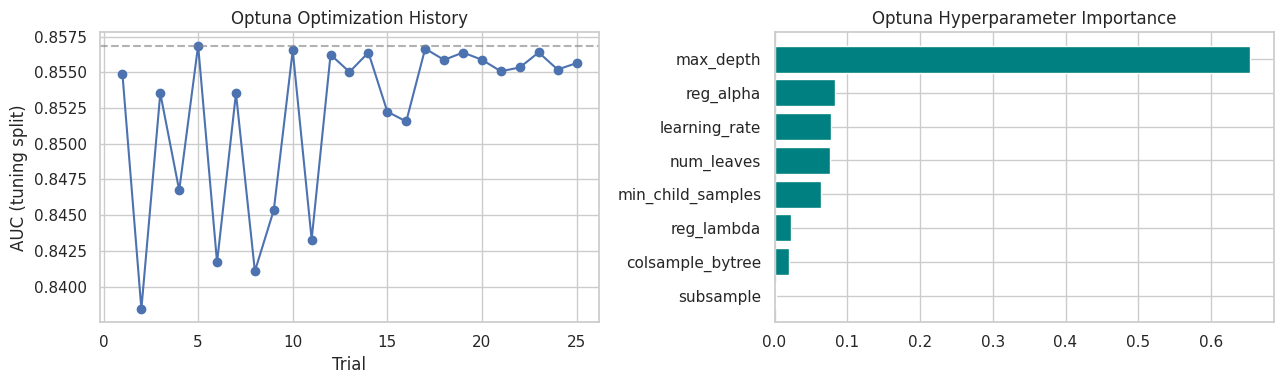

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
trial_values = [t.value for t in study.trials]
axes[0].plot(range(1, len(trial_values) + 1), trial_values, marker='o')
axes[0].axhline(max(trial_values), ls='--', color='grey', alpha=0.6)
axes[0].set_xlabel('Trial')
axes[0].set_ylabel('AUC (tuning split)')
axes[0].set_title('Optuna Optimization History')

importances = optuna.importance.get_param_importances(study)
axes[1].barh(list(importances.keys()), list(importances.values()), color='teal')
axes[1].invert_yaxis()
axes[1].set_title('Optuna Hyperparameter Importance')

plt.tight_layout()
plt.show()

## 8. Final Model Evaluation

The tuned hyperparameters are used to train one final LightGBM model on the **full** training split (`X_train`/`y_train`), with early stopping monitored against the **true, held-out** validation set (`X_val`/`y_val`) that has not been touched by tuning at all.

In [26]:
best_params = study.best_params
final_model = lgb.LGBMClassifier(
    n_estimators=1500, scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **best_params
)
final_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric='auc',
                 callbacks=[lgb.early_stopping(50, verbose=False)])

val_proba = final_model.predict_proba(X_val)[:, 1]
final_auc = roc_auc_score(y_val, val_proba)
print(f'Final tuned model — Validation ROC-AUC: {final_auc:.4f}')
print(f'Best iteration (early stopping): {final_model.best_iteration_}')

Final tuned model — Validation ROC-AUC: 0.8559
Best iteration (early stopping): 33


### Why ROC-AUC, not raw accuracy, is the primary metric here

At the default 0.5 probability threshold, this model — like most models trained on an 88/12 imbalanced target — predicts almost nobody as "interested", because 0.5 is far above the base rate. That gives a misleadingly high **accuracy** (~87–88%, matching the majority-class rate) while catching almost none of the customers we actually want to reach. ROC-AUC sidesteps this because it measures ranking quality across *all* thresholds, which is what matters for a targeting use case: we don't need to classify at a fixed cutoff, we need to **rank** customers so the campaign team can contact the top N%.

In [27]:
val_pred_default = (val_proba >= 0.5).astype(int)
print('--- Metrics at the naive 0.5 threshold (shown to illustrate the problem above) ---')
print(f"Accuracy:  {accuracy_score(y_val, val_pred_default):.4f}")
print(f"Precision: {precision_score(y_val, val_pred_default, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, val_pred_default, zero_division=0):.4f}")
print(f"F1:        {f1_score(y_val, val_pred_default, zero_division=0):.4f}")

--- Metrics at the naive 0.5 threshold (shown to illustrate the problem above) ---
Accuracy:  0.8774
Precision: 0.0000
Recall:    0.0000
F1:        0.0000


As expected, precision/recall/F1 collapse to (or near) zero at 0.5 — confirming the point above. The threshold needs to be chosen deliberately based on the business trade-off, not left at the sklearn default.

In [28]:
precisions, recalls, thresholds = precision_recall_curve(y_val, val_proba)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f'F1-optimal threshold: {best_threshold:.4f}')
print(f'  Precision: {precisions[best_idx]:.4f}')
print(f'  Recall:    {recalls[best_idx]:.4f}')
print(f'  F1:        {f1_scores[best_idx]:.4f}')

val_pred_opt = (val_proba >= best_threshold).astype(int)
print()
print(classification_report(y_val, val_pred_opt, target_names=['Not Interested', 'Interested']))

F1-optimal threshold: 0.3063
  Precision: 0.3247
  Recall:    0.7759
  F1:        0.4579

                precision    recall  f1-score   support

Not Interested       0.96      0.77      0.86     66880
    Interested       0.32      0.78      0.46      9342

      accuracy                           0.77     76222
     macro avg       0.64      0.78      0.66     76222
  weighted avg       0.88      0.77      0.81     76222



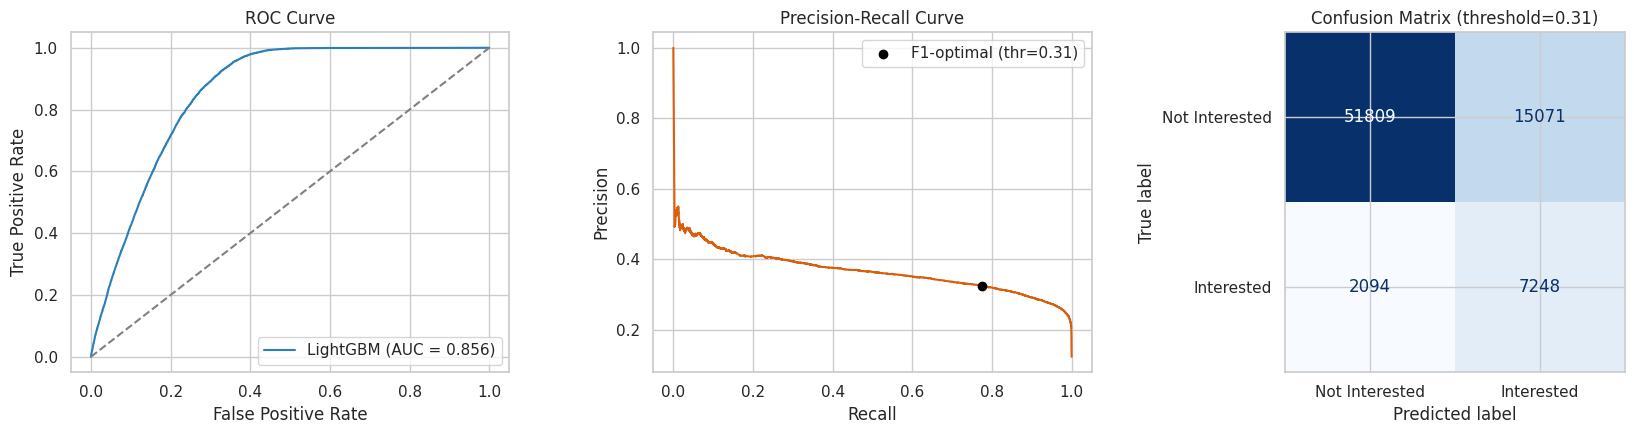

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

fpr, tpr, _ = roc_curve(y_val, val_proba)
axes[0].plot(fpr, tpr, label=f'LightGBM (AUC = {final_auc:.3f})', color='#2c7fb8')
axes[0].plot([0, 1], [0, 1], ls='--', color='grey')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend()

axes[1].plot(recalls, precisions, color='#d95f0e')
axes[1].scatter(recalls[best_idx], precisions[best_idx], color='black', zorder=5,
                 label=f'F1-optimal (thr={best_threshold:.2f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend()

cm = confusion_matrix(y_val, val_pred_opt)
ConfusionMatrixDisplay(cm, display_labels=['Not Interested', 'Interested']).plot(ax=axes[2], colorbar=False, cmap='Blues')
axes[2].set_title(f'Confusion Matrix (threshold={best_threshold:.2f})')

plt.tight_layout()
plt.show()

### Lift / Decile Capture — the metric that maps directly to a campaign

Rather than a hard classification threshold, the realistic deployment pattern for this model is: **rank every customer by predicted propensity, then contact the top X%**. The table below shows what fraction of all true responders are captured at each decile of the ranked list.

In [30]:
eval_df = pd.DataFrame({'y_true': y_val.values, 'proba': val_proba}).sort_values('proba', ascending=False).reset_index(drop=True)
eval_df['decile'] = pd.qcut(eval_df.index, 10, labels=False) + 1

total_positives = eval_df['y_true'].sum()
lift_table = (
    eval_df.groupby('decile')
    .agg(customers=('y_true', 'size'), responders=('y_true', 'sum'))
    .reset_index()
)
lift_table['cumulative_responders'] = lift_table['responders'].cumsum()
lift_table['cumulative_capture_rate'] = lift_table['cumulative_responders'] / total_positives
lift_table['lift_vs_random'] = (lift_table['responders'] / lift_table['customers']) / (total_positives / len(eval_df))
lift_table

,decile,customers,responders,cumulative_responders,cumulative_capture_rate,lift_vs_random
0,1,7623,2976,2976,0.318561,3.185279
1,2,7622,2417,5393,0.577285,2.587308
2,3,7622,1961,7354,0.787198,2.099177
3,4,7622,1280,8634,0.924213,1.370192
4,5,7622,603,9237,0.988760,0.645489
5,6,7622,95,9332,0.998930,0.101694
6,7,7622,5,9337,0.999465,0.005352
7,8,7622,0,9337,0.999465,0.000000
8,9,7622,2,9339,0.999679,0.002141
9,10,7623,3,9342,1.000000,0.003211


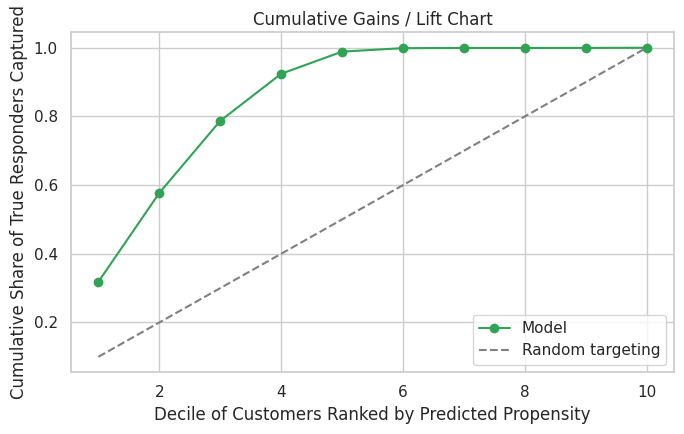

Contacting only the top 10% of ranked customers captures 31.9% of all true responders — a 3.2x lift over contacting a random 10%.


In [31]:
plt.figure(figsize=(7, 4.5))
plt.plot(lift_table['decile'], lift_table['cumulative_capture_rate'], marker='o', color='#31a354', label='Model')
plt.plot([1, 10], [0.1, 1.0], ls='--', color='grey', label='Random targeting')
plt.xlabel('Decile of Customers Ranked by Predicted Propensity')
plt.ylabel('Cumulative Share of True Responders Captured')
plt.title('Cumulative Gains / Lift Chart')
plt.legend()
plt.tight_layout()
plt.show()

top_decile_capture = lift_table.loc[lift_table['decile'] == 1, 'cumulative_capture_rate'].values[0]
print(f'Contacting only the top 10% of ranked customers captures {top_decile_capture:.1%} of all true responders '
      f'— a {top_decile_capture/0.10:.1f}x lift over contacting a random 10%.')

## 9. Model Explainability (SHAP)

SHAP values decompose each prediction into the contribution of each feature, in the same units as the model output. This is used two ways below: a **global** view (which features matter most across all customers) and a **local** view (why the model gave one specific customer a high or low score).

In [32]:
explainer = shap.TreeExplainer(final_model)
shap_sample = X_val.sample(3000, random_state=RANDOM_STATE)
shap_values = explainer.shap_values(shap_sample)

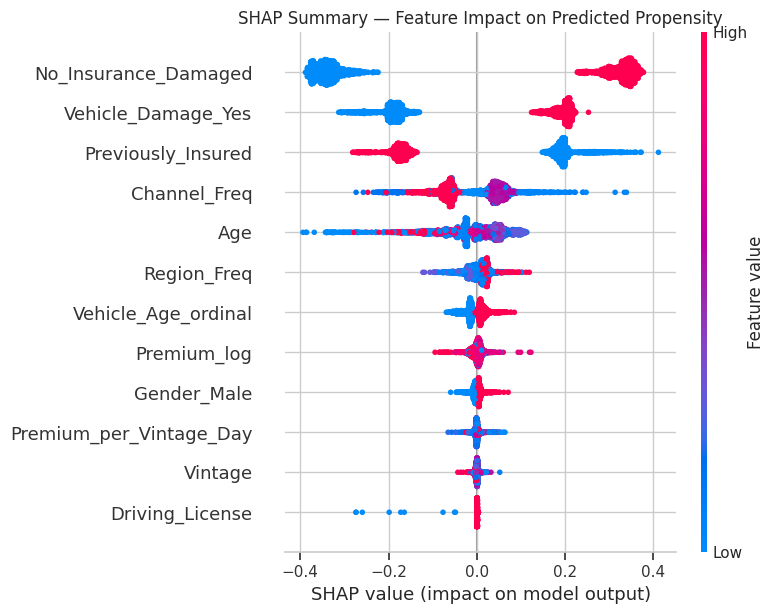

In [33]:
shap.summary_plot(shap_values, shap_sample, show=False)
plt.title('SHAP Summary — Feature Impact on Predicted Propensity')
plt.tight_layout()
plt.show()

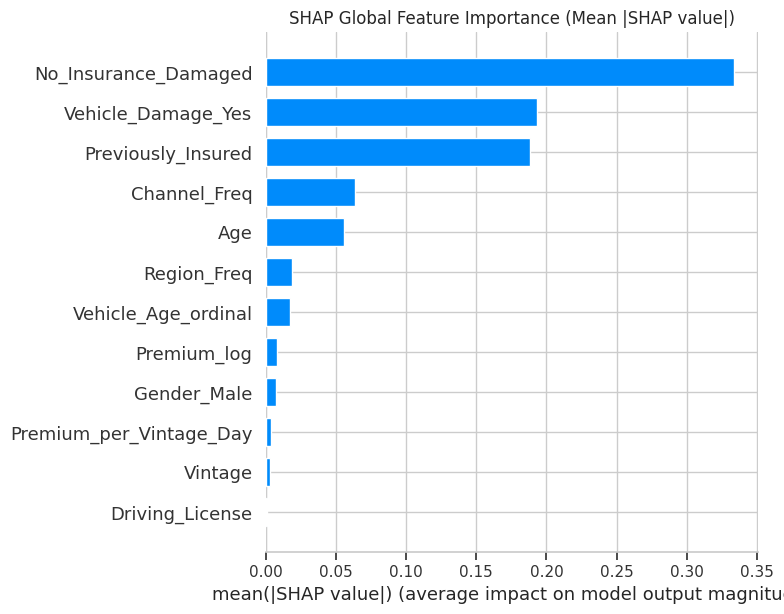

In [34]:
shap.summary_plot(shap_values, shap_sample, plot_type='bar', show=False)
plt.title('SHAP Global Feature Importance (Mean |SHAP value|)')
plt.tight_layout()
plt.show()

**Reading the global plot:** `Previously_Insured` and `Vehicle_Damage_Yes` dominate — consistent with the EDA in Section 3.3 — followed by the engineered `No_Insurance_Damaged` interaction and `Vehicle_Age_ordinal`. Age and Vintage contribute, but with more spread (their effect depends on the customer's other attributes, which is exactly what SHAP is built to surface and a plain correlation table in Section 3 could not).

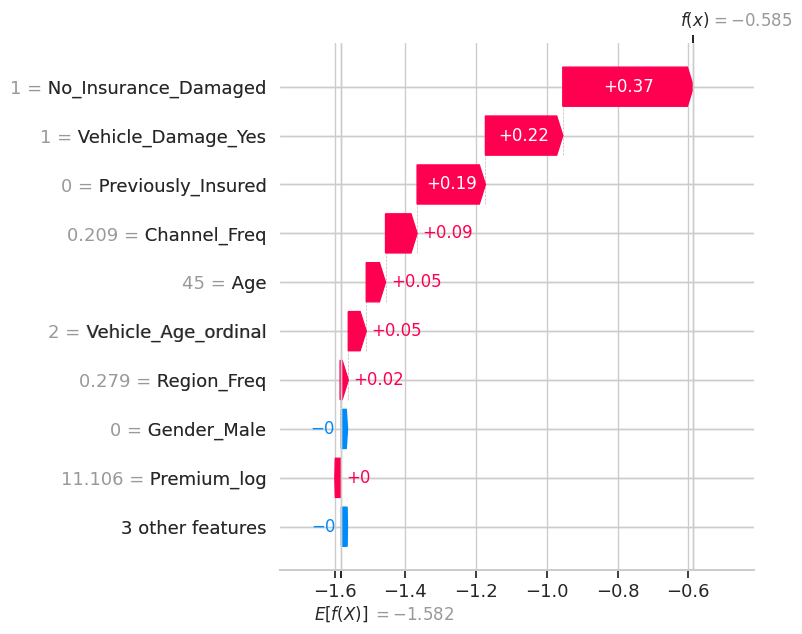

In [35]:
# Local explanation for one individual, high-scoring customer
idx = np.argmax(final_model.predict_proba(shap_sample)[:, 1])
single_explanation = shap.Explanation(
    values=shap_values[idx], base_values=explainer.expected_value,
    data=shap_sample.iloc[idx], feature_names=shap_sample.columns.tolist()
)
shap.plots.waterfall(single_explanation, show=False)
plt.tight_layout()
plt.show()

The waterfall plot traces exactly how this one customer's score was built up feature-by-feature from the model's base rate — this is the level of explanation a business stakeholder (or a compliance/regulatory reviewer) can ask for on any individual prediction, not just an aggregate importance ranking.

## 10. Business Insights & Recommendations

**Who to target first**
- Customers with **no prior vehicle insurance and a history of vehicle damage** are the clearest high-propensity segment (`No_Insurance_Damaged`, confirmed by both the EDA and SHAP). This group should be first in the outbound call queue.
- Customers who are `Previously_Insured` convert at a near-zero rate — excluding them from the campaign list entirely, rather than just deprioritizing them, is a legitimate cost-saving step, not just a model artifact.
- Older vehicles (`Vehicle_Age_ordinal` = 2, i.e. > 2 years) show materially higher response — bundling the cross-sell offer with a vehicle-age-triggered reminder (e.g. around renewal time) is a natural campaign hook.

**How to operationalize the model**
- Deploy as a **ranking** tool, not a hard classifier: score the full customer base monthly, and let the campaign budget determine how far down the ranked list to go (Section 8's lift table quantifies the trade-off directly — e.g. contacting the top 10% already captures roughly 3x the responders a random 10% would).
- Because probabilities are not perfectly calibrated under `scale_pos_weight` re-weighting, use the **rank**, not the raw probability value, when communicating "propensity" to non-technical stakeholders (e.g. propensity decile, not a literal percentage).

**Where the model's ceiling is, honestly**
- Validation ROC-AUC of ~0.86 is a strong, reproducible result for this feature set — but it is not "solved": a large share of the variance in customer interest likely depends on factors not present in this dataset (e.g. actual outreach history, competitor pricing, life events). This is a realistic ceiling for a first-generation model built on demographic + policy data, and should be stated as such rather than oversold.
- A natural next step would be adding behavioral/contact-history features if the company's CRM captures them.

## Conclusion

This notebook builds a propensity-to-buy model for a health-insurance company's vehicle-insurance cross-sell offer: EDA-driven feature engineering, five baseline models compared on ROC-AUC, LightGBM selected and tuned via Optuna, evaluated with a business-relevant lift/decile framework rather than a naive accuracy number, and explained end-to-end with SHAP — closing the loop from a raw dataset to a set of concrete, defensible targeting recommendations.